In [ ]:
#activity 1
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

(x_train_full, y_train_full), (x_test_full, y_test_full) = tf.keras.datasets.mnist.load_data()

# Define a function to select an equal number of images from each digit class
def balanced_subset(images, labels, per_class, seed=SEED):
    # Create a random number generator using the given seed
    rng = np.random.default_rng(seed)
    chosen = []

    # Loop through all 10 digit classes (0 to 9)
    for class_id in range(10):
        indices = np.where(labels == class_id)[0]
        # Randomly select the required number of images from this digit
        # replace=False ensures that the same image is not selected twice
        chosen.extend(rng.choice(indices, size=per_class, replace=False))

    chosen = np.array(chosen)
    rng.shuffle(chosen)
    return images[chosen], labels[chosen]

# Select 100 training images for each digit class
# 10 classes × 100 images = 1,000 training images
x_train_small, y_train_small = balanced_subset(x_train_full, y_train_full, 100)

# Select 20 test images for each digit class
# Use a different seed to make the test selection independent
# 10 classes × 20 images = 200 test images
x_test, y_test = balanced_subset(x_test_full, y_test_full, 20, seed=SEED + 1)

print("Selected training images:", x_train_small.shape)
print("Selected test images:", x_test.shape)
print("Training examples per class:", np.bincount(y_train_small))
print("Test examples per class:", np.bincount(y_test))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Selected training images: (1000, 28, 28)
Selected test images: (200, 28, 28)
Training examples per class: [100 100 100 100 100 100 100 100 100 100]
Test examples per class: [20 20 20 20 20 20 20 20 20 20]


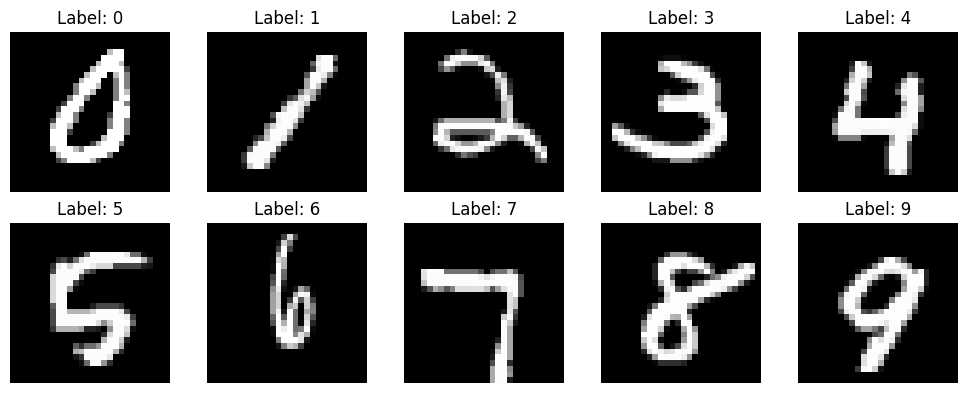

Image shape: (28, 28)
Pixel range: 0 to 255


In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    idx = np.where(y_train_small == digit)[0][0]
    ax.imshow(x_train_small[idx], cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image shape:", x_train_small[0].shape)
print("Pixel range:", x_train_small.min(), "to", x_train_small.max())


In [ ]:
#activity2
# Scale pixel values to [0, 1] and add the grayscale channel dimension
x_train_small = x_train_small.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# newaxis adds the required channel dimension
x_train_small = x_train_small[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# splitting into train and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train_small,
    y_train_small,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_small
)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Pixel range after scaling:", x_train.min(), "to", x_train.max())


Training: (800, 28, 28, 1) (800,)
Validation: (200, 28, 28, 1) (200,)
Test: (200, 28, 28, 1) (200,)
Pixel range after scaling: 0.0 to 1.0


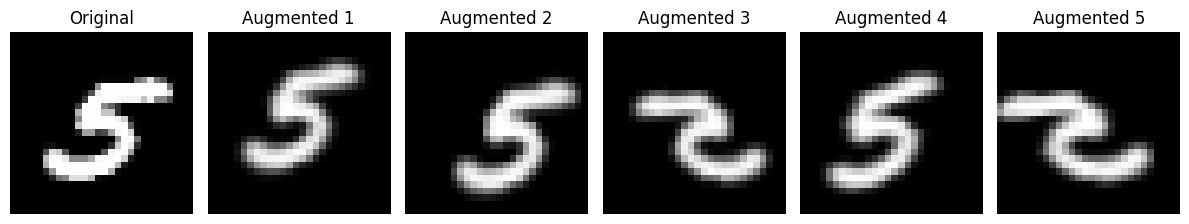

In [ ]:
#activity 3
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        0.08, fill_mode="constant"
    ),
    tf.keras.layers.RandomTranslation(
        0.08, 0.08, fill_mode="constant"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.1, 0.1),
        width_factor=(-0.1, 0.1),
        fill_mode="constant"
    ),
    tf.keras.layers.RandomContrast(0.2),
    tf.keras.layers.RandomFlip("horizontal"),
], name="image_augmentation")

# Select one grayscale image
sample = x_train[0:1]

# Generate five different augmented versions
augmented = augmentation(
    tf.repeat(sample, repeats=5, axis=0),
    training=True
)

# Display original and augmented images
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
axes[0].imshow(sample[0, ..., 0], cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(5):
    axes[i + 1].imshow(
        augmented[i, ..., 0].numpy(),
        cmap="gray"
    )
    axes[i + 1].set_title(f"Augmented {i+1}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#activity 4
def build_dense_model():
  model = tf.keras.Sequential([
      tf.keras.layers.Input(shape=(28, 28, 1)),
      tf.keras.layers.Flatten(),
      tf.keras.layers.Dense(128, activation="relu"),
      tf.keras.layers.Dropout(0.2),
      tf.keras.layers.Dense(10, activation="softmax"),
  ])
  model.compile(
      optimizer="adam",
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"],
  )
  return model


dense_model = build_dense_model()
dense_model.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

dense_history = dense_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    # callbacks=[early_stop],
    verbose=1,
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4575 - loss: 1.7619 - val_accuracy: 0.7800 - val_loss: 1.0908
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7750 - loss: 0.9043 - val_accuracy: 0.8100 - val_loss: 0.6677
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8325 - loss: 0.6102 - val_accuracy: 0.8700 - val_loss: 0.5247
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8813 - loss: 0.4723 - val_accuracy: 0.8700 - val_loss: 0.4693
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8963 - loss: 0.3902 - val_accuracy: 0.8900 - val_loss: 0.4221
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9212 - loss: 0.3252 - val_accuracy: 0.8950 - val_loss: 0.3996
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9350 - loss: 0.2745 - val_accuracy: 0.8950 - val_loss: 0.3927
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9463 - loss: 0.2376 - val_accuracy: 0.9150 - val_loss

In [ ]:
#activity 5
def build_cnn_model(use_augmentation=False):
    layers = [tf.keras.layers.Input(shape=(28, 28, 1))]
    if use_augmentation:
        layers.append(augmentation)
    layers += [
        tf.keras.layers.Conv2D(
            16, kernel_size=3, activation="relu", padding="same"
        ),  # enough padding is added so it remains same
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(
            32, kernel_size=3, activation="relu", padding="same"
        ),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10, activation="softmax"),
    ]
    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


cnn_model = build_cnn_model(use_augmentation=False)
cnn_model.summary()

cnn_history = cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    # callbacks=[early_stop],
    verbose=1,
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.3450 - loss: 2.0335 - val_accuracy: 0.6600 - val_loss: 1.4793
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6175 - loss: 1.1874 - val_accuracy: 0.7900 - val_loss: 0.7175
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7837 - loss: 0.7064 - val_accuracy: 0.8500 - val_loss: 0.4715
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8250 - loss: 0.5302 - val_accuracy: 0.8900 - val_loss: 0.3832
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8750 - loss: 0.4070 - val_accuracy: 0.9000 - val_loss: 0.3121
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8825 - loss: 0.3417 - val_accuracy: 0.9150 - val_loss: 0.2889
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9187 - loss: 0.2724 - val_accuracy: 0.9150 - val_loss: 0.2734
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9350 - loss: 0.2339 - val_accuracy: 0.9200 - v

In [ ]:
#activity 6
aug_cnn_model = build_cnn_model(use_augmentation=True)

aug_cnn_history = aug_cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    # callbacks=[early_stop],
    verbose=1,
)


Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.1950 - loss: 2.2225 - val_accuracy: 0.5600 - val_loss: 1.9008
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.3675 - loss: 1.8938 - val_accuracy: 0.6550 - val_loss: 1.2565
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4675 - loss: 1.6087 - val_accuracy: 0.7350 - val_loss: 0.9522
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.5500 - loss: 1.3436 - val_accuracy: 0.7850 - val_loss: 0.7480
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5825 - loss: 1.2334 - val_accuracy: 0.8000 - val_loss: 0.6265
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6175 - loss: 1.1477 - val_accuracy: 0.8250 - val_loss: 0.5790
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6463 - loss: 1.0204 - val_accuracy: 0.8400 - val_loss: 0.5055
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.6538 - loss: 0.9970 - val_accuracy: 0.8650 - v

In [ ]:
#activity 7
models = {
    "Fully connected NN": dense_model,
    "Basic CNN": cnn_model,
    "CNN + augmentation": aug_cnn_model,
}

results = {}

for name, model in models.items():
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    results[name] = {"test_loss": loss, "test_accuracy": accuracy}

print("Test results")
for name, result in results.items():
    print(
        f"{name:22s} | loss={result['test_loss']:.4f} | accuracy={result['test_accuracy']:.3f}"
    )


Test results
Fully connected NN     | loss=0.4546 | accuracy=0.890
Basic CNN              | loss=0.2150 | accuracy=0.945
CNN + augmentation     | loss=0.3586 | accuracy=0.880


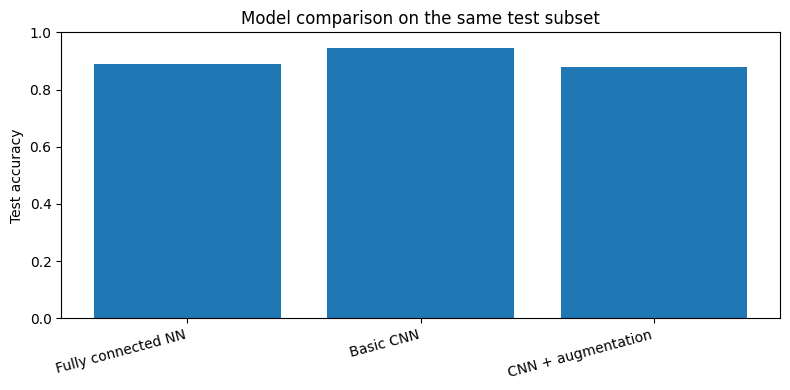

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
names = list(results.keys())
accuracies = [results[name]["test_accuracy"] for name in names]

plt.bar(names, accuracies)
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("Model comparison on the same test subset")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
#get the dataset and imports:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
!pip install importlib_resources

# Load the dataset
data, info = tfds.load("oxford_iiit_pet", with_info=True, as_supervised=False)
print(info)
# Set random seeds for reproducibility
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.82E7T3_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.82E7T3_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='/root/tensorflow_datasets/oxford_iiit_pet/4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text(shape=(), dtype=string),
       

In [ ]:

# Load Oxford-IIIT Pet dataset
# 80% training, 20% validation, and official test split
(datasets, info) = tfds.load(
    "oxford_iiit_pet",
    split=["train[:80%]", "train[80%:]", "test"],
    with_info=True,
    as_supervised=True
)

train_ds, val_ds, test_ds = datasets

print(info)
print("Number of classes:", info.features["label"].num_classes)

tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='/root/tensorflow_datasets/oxford_iiit_pet/4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text(shape=(), dtype=string),
        'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'label': ClassLab

In [ ]:
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = info.features["label"].num_classes

def preprocess_image(image, label):
    # Resize every image to the same dimensions
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # Normalize pixel values from 0-255 to 0-1
    image = image / 255.0

    return image, label

# Apply preprocessing
train_ds = train_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle training images and create batches
train_ds = train_ds.shuffle(
    1000, seed=SEED
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)

Image size: 64 x 64
Number of classes: 37
Batch size: 32


In [ ]:
def build_cnn_model(model_type="basic"):

    layers = [
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    ]

    # Model 1: Basic CNN
    if model_type == "basic":
        layers += [
            tf.keras.layers.Conv2D(
                16, kernel_size=3,
                activation="relu", padding="same"
            ),
            tf.keras.layers.MaxPooling2D(pool_size=2),

            tf.keras.layers.Conv2D(
                32, kernel_size=3,
                activation="relu", padding="same"
            ),
            tf.keras.layers.MaxPooling2D(pool_size=2)
        ]

    # Model 2: Deeper CNN
    elif model_type == "deeper":
        layers += [
            tf.keras.layers.Conv2D(
                16, kernel_size=3,
                activation="relu", padding="same"
            ),
            tf.keras.layers.MaxPooling2D(pool_size=2),

            tf.keras.layers.Conv2D(
                32, kernel_size=3,
                activation="relu", padding="same"
            ),
            tf.keras.layers.MaxPooling2D(pool_size=2),

            # Third convolutional layer
            tf.keras.layers.Conv2D(
                64, kernel_size=3,
                activation="relu", padding="same"
            )
        ]

    # Model 3: Wider CNN
    elif model_type == "wider":
        layers += [
            tf.keras.layers.Conv2D(
                32, kernel_size=3,
                activation="relu", padding="same"
            ),
            tf.keras.layers.MaxPooling2D(pool_size=2),

            tf.keras.layers.Conv2D(
                64, kernel_size=3,
                activation="relu", padding="same"
            ),
            tf.keras.layers.MaxPooling2D(pool_size=2)
        ]

    # Common layers for all models
    layers += [
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ]

    model = tf.keras.Sequential(layers)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
models = {
    "Basic CNN": build_cnn_model("basic"),
    "Deeper CNN": build_cnn_model("deeper"),
    "Wider CNN": build_cnn_model("wider")
}

results = {}
histories = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Show model architecture and parameter count
    model.summary()

    # Train the model
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    histories[name] = history

    # Evaluate on the same test dataset
    test_loss, test_accuracy = model.evaluate(
        test_ds,
        verbose=0
    )

    results[name] = {
        "training_accuracy": history.history["accuracy"][-1],
        "validation_accuracy": history.history["val_accuracy"][-1],
        "test_accuracy": test_accuracy,
        "test_loss": test_loss,
        "trainable_parameters": model.count_params()
    }

print("\nMODEL COMPARISON")

for name, result in results.items():
    print(f"\n{name}")
    print(f"Training Accuracy:   {result['training_accuracy']:.4f}")
    print(f"Validation Accuracy: {result['validation_accuracy']:.4f}")
    print(f"Test Accuracy:       {result['test_accuracy']:.4f}")
    print(f"Test Loss:           {result['test_loss']:.4f}")
    print(f"Trainable Parameters: {result['trainable_parameters']:,}")


Training: Basic CNN


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       524,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 37)             │         2,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 531,845 (2.03 MB)

 Trainable params: 531,845 (2.03 MB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 1,070,437 (4.08 MB)

 Trainable params: 1,070,437 (4.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 276ms/step - accuracy: 0.0262 - loss: 3.6189 - val_accuracy: 0.0380 - val_loss: 3.6051
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 41s 258ms/step - accuracy: 0.0486 - loss: 3.5474 - val_accuracy: 0.0611 - val_loss: 3.5107
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 251ms/step - accuracy: 0.0938 - loss: 3.3627 - val_accuracy: 0.1005 - val_loss: 3.3859
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 252ms/step - accuracy: 0.1573 - loss: 3.0996 - val_accuracy: 0.1060 - val_loss: 3.2971
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 255ms/step - accuracy: 0.2351 - loss: 2.7767 - val_accuracy: 0.1304 - val_loss: 3.1966
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 256ms/step - accuracy: 0.3274 - loss: 2.4065 - val_accuracy: 0.1182 - val_loss: 3.2832
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 253ms/step - accuracy: 0.4205 - loss: 2.0206 - val_accuracy: 0.1304 - val_loss: 3.4055
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 284ms/step - accuracy: 0.5194 - loss: 1.6470 - val_accu

In [ ]:
import pandas as pd

comparison = pd.DataFrame(results).T

comparison["training_accuracy"] *= 100
comparison["validation_accuracy"] *= 100
comparison["test_accuracy"] *= 100

comparison = comparison.rename(columns={
    "training_accuracy": "Training Accuracy (%)",
    "validation_accuracy": "Validation Accuracy (%)",
    "test_accuracy": "Test Accuracy (%)",
    "test_loss": "Test Loss",
    "trainable_parameters": "Trainable Parameters"
})

print(comparison.round(2))

            Training Accuracy (%)  Validation Accuracy (%)  Test Accuracy (%)  \
Basic CNN                   33.97                    11.82              12.59   
Deeper CNN                  50.51                     8.97               9.54   
Wider CNN                   68.68                    11.96              11.28   

            Test Loss  Trainable Parameters  
Basic CNN        3.37              531845.0  
Deeper CNN       4.32             1074629.0  
Wider CNN        4.38             1070437.0  


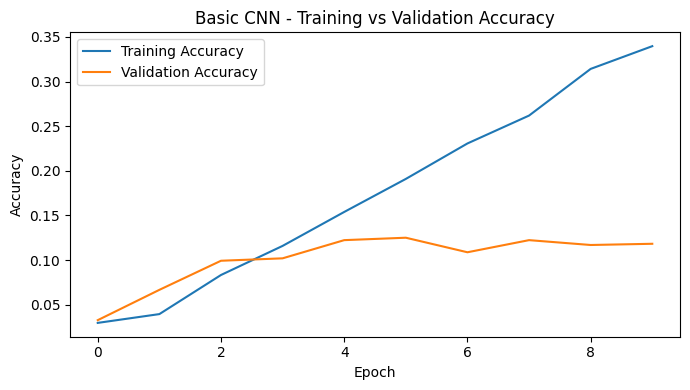

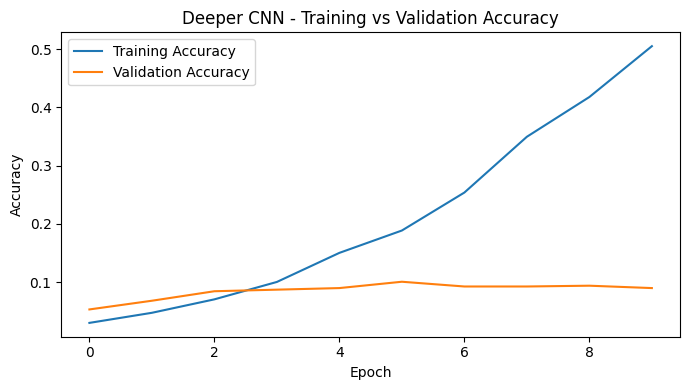

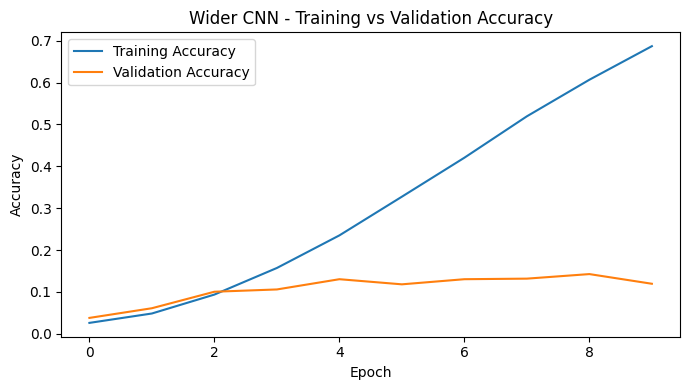

In [ ]:
for name, history in histories.items():

    plt.figure(figsize=(7, 4))

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(name + " - Training vs Validation Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

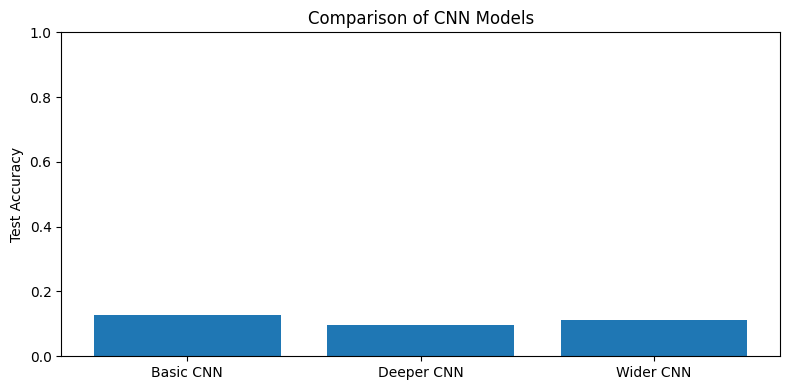

In [ ]:
names = list(results.keys())
accuracies = [
    results[name]["test_accuracy"] for name in names
]

plt.figure(figsize=(8, 4))
plt.bar(names, accuracies)
plt.ylim(0, 1)
plt.ylabel("Test Accuracy")
plt.title("Comparison of CNN Models")
plt.tight_layout()
plt.show()